In [1]:
import numpy as np
import argparse
import os
import importlib
import matplotlib.pyplot as plt

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [2]:
import simulate_CCE_time

In [3]:
args = argparse.Namespace(        
            seed=123,        
            N_charges=150,        
            N_repeat=150,        
            alpha=1.6e-11,     
            FCCD = 0.095,   
            sigma_R = 60,
            N_sat = 1e14,
            T_ann=623,        
            t_ann=18*60,        
            output="library"
        )

In [4]:
params = simulate_CCE_time.update_parameters(args)

cells, saturation_depth, px, py, pz, pR, lithium_distribution = (
        simulate_CCE_time.generate_lithium(params)
    )

Calculating Li concentration: 100%|██████████| 66/66 [00:00<00:00, 117298.33it/s]


60 um


Generating Li agglomerates: 100%|██████████| 66/66 [00:00<00:00, 4343.29it/s]

Total theoretical primary Li (R=20 um) = 1163
Total theoretical agglomerates = 460
Total theoretical remaining 20 um particles = 39
Total accepted agglomerates = 460
Total accepted remaining 20 um particles = 39
Total accepted Li particles = 499


In [31]:
(
    x,
    CCE_matrix,
    CCE_mean,
    CCE_std,
    elapsed_ns,
    status,
) = simulate_CCE_time.simulate_CCE(
    cells,
    saturation_depth,
    px,
    py,
    pz,
    pR,
    args,
)


Starting CCE and timing simulation...



CCE depth: 100%|██████████| 22/22 [05:38<00:00, 15.39s/it]


Trajectory outcomes:
Still moving at t_max: 607
Collected at FCCD: 209098
Lost in dead layer: 54754
Lost on lithium: 230541


In [32]:
filename = simulate_CCE_time.save_results(
    x,
    CCE_matrix,
    CCE_mean,
    CCE_std,
    saturation_depth,
    px,
    py,
    pz,
    pR,
    elapsed_ns,
    status,
    args,
    simulate_CCE_time.update_parameters(args),
)


Saved: library/curve_000123.npz



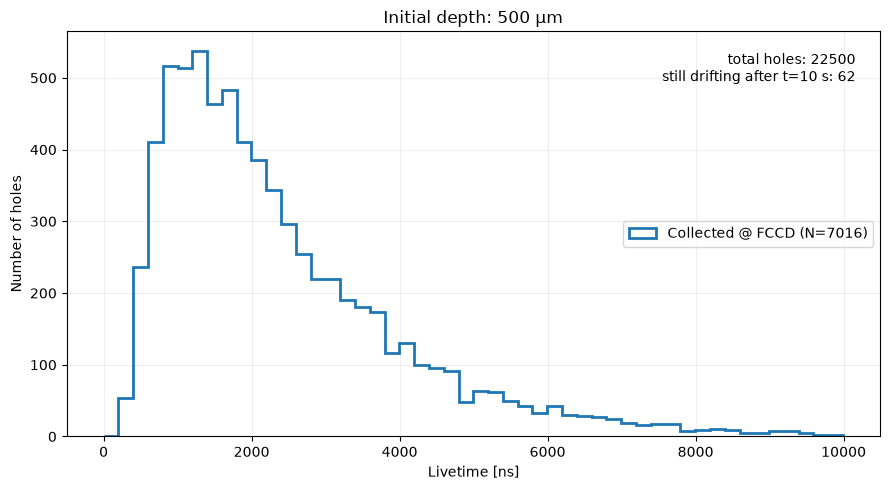

Depth: 500 µm
Collected @ FCCD: N=7016, mean=2374.805 µs, mode=1932.000 µs


In [38]:

depth_um = 500  # µm
dt = 1

# Seleziona la profondità simulata più vicina.
depths_um = np.asarray(x) * 1e4
i = np.argmin(np.abs(depths_um - depth_um))

# Unisce ripetizioni e lacune alla profondità selezionata.
times_ns = elapsed_ns[i].ravel()
outcomes = status[i].ravel()

# Conversione ns -> µs
times_us = times_ns 

# ============================================================
# BIN COMUNI PER TUTTI GLI ESITI TERMINALI
# ============================================================

terminated = outcomes != 0

if not np.any(terminated):
    print("no holed lost/collected at this depth .")

else:
    max_time_us = times_us[terminated].max()

    # Gestisce anche il caso di soli eventi a t = 0.
    upper_limit = max(max_time_us, float(dt) / 1000)
    bins = np.linspace(0, upper_limit, 51)

    fig, ax = plt.subplots(figsize=(9, 5))

    categories = [
        (1, "Collected @ FCCD", "tab:blue"),
       # (2, "Lost 1st bin", "tab:orange"),
       # (3, "Lost by recombination", "tab:red"),
    ]

    for code, label, color in categories:

        selected = times_us[outcomes == code]

        if selected.size == 0:
            continue

        ax.hist(
            selected,
            bins=bins,
            histtype="step",
            linewidth=2,
            color=color,
            label=f"{label} (N={selected.size})",
        )

    n_unresolved = np.count_nonzero(outcomes == 0)

    ax.set_xlabel("Livetime [ns]")
    ax.set_ylabel("Number of holes")
    ax.set_title(
        f"Initial depth: {depths_um[i]:.0f} µm"
    )

    ax.text(
        0.97,
        0.95,
        f"total holes: {outcomes.size}\n"
        f"still drifting after t=10 s: {n_unresolved}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=10,
    )

    ax.legend(loc="best")
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

    print(f"Depth: {depths_um[i]:.0f} µm")

    for code, label, _ in categories:
        selected = times_us[outcomes == code]

        if selected.size:
            print(
                f"{label}: N={selected.size}, "
                f"mean={selected.mean():.3f} µs, "
                f"mode={np.median(selected):.3f} µs"
            )
            

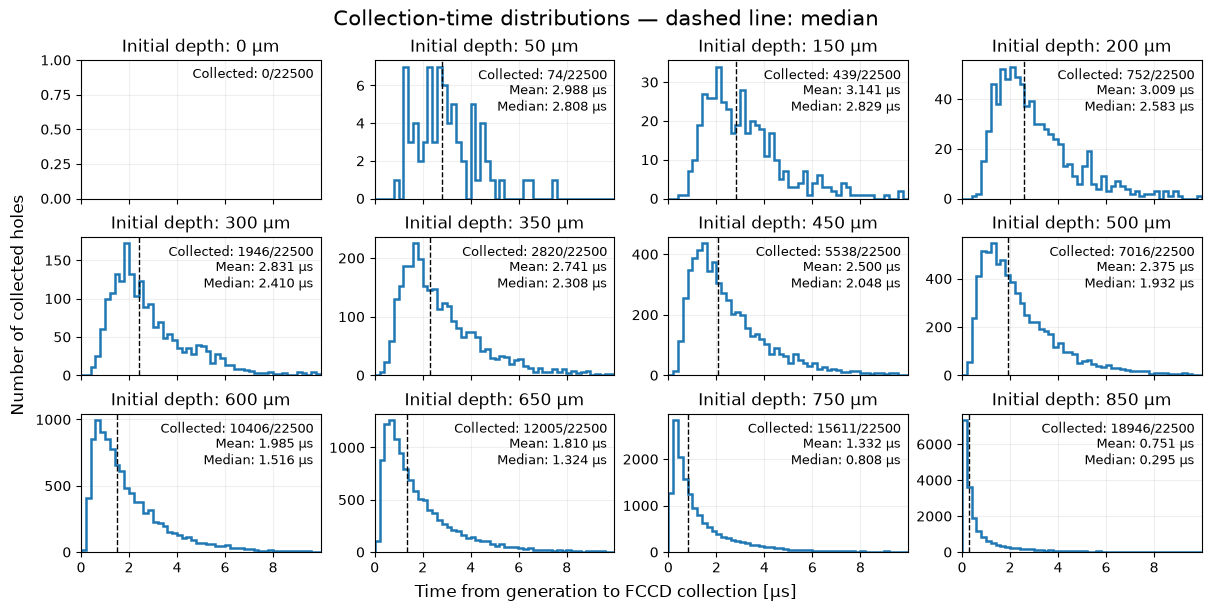

In [40]:
depths_um = np.asarray(x[:-4]) * 1e4

# 12 posizioni distribuite tra quelle simulate.
indices = np.unique(
    np.linspace(
        0,
        len(depths_um) - 1,
        min(12, len(depths_um)),
        dtype=int,
    )
)

# In alternativa, scegli manualmente gli indici:
# indices = np.arange(12)

# Tempi delle sole lacune raccolte, per ciascuna posizione.
collected_times = [
    elapsed_ns[i][status[i] == 1] / 1000
    for i in indices
]

# Bin comuni per confrontare le distribuzioni.
nonempty = [t for t in collected_times if t.size > 0]

if nonempty:
    max_time_us = max(t.max() for t in nonempty)
else:
    max_time_us = 0.0

# Evita bin degeneri anche con soli tempi nulli.
upper_limit = max(max_time_us, 1e-3)
bins = np.linspace(0, upper_limit, 51)

fig, axes = plt.subplots(
    3,
    4,
    figsize=(12, 6),
    sharex=True,
    #sharey=True,
    constrained_layout=True,
)

for ax, i, times_us in zip(
    axes.flat,
    indices,
    collected_times,
):
    total = status[i].size
    collected = times_us.size

    if collected > 0:

        ax.hist(
            times_us,
            bins=bins,
            histtype="step",
            linewidth=1.8,
            color="tab:blue",
        )

        ax.axvline(
            np.median(times_us),
            color="black",
            linestyle="--",
            linewidth=1,
        )

        annotation = (
            f"Collected: {collected}/{total}\n"
            f"Mean: {times_us.mean():.3f} µs\n"
            f"Median: {np.median(times_us):.3f} µs"
        )

    else:
        annotation = f"Collected: 0/{total}"

    ax.set_title(
        f"Initial depth: {depths_um[i]:.0f} µm"
    )

    ax.text(
        0.97,
        0.95,
        annotation,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
    )

    ax.set_xlim(0, upper_limit)
    ax.grid(alpha=0.2)

# Nasconde eventuali pannelli senza posizione associata.
for ax in axes.flat[len(indices):]:
    ax.set_visible(False)

fig.supxlabel("Time from generation to FCCD collection [µs]")
fig.supylabel("Number of collected holes")
fig.suptitle(
    "Collection-time distributions — dashed line: median",
    fontsize=15,
)

plt.show()